# Machine Learning: Practical Session 1
## Python for Data Exploration and Preprocessing
National Higher School of Advanced Technologies | First-year Master's | 2026-2027


In [81]:
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler,
    normalize, Binarizer, OrdinalEncoder, LabelEncoder, OneHotEncoder,
)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42
DATA_DIR = Path(".")   

---
# Exercise 1: Exploring a tabular dataset and creating data splits

### 1. Load the CSV into a DataFrame named `D`

In [82]:
iris_path = DATA_DIR / "Iris_Dataset.csv"
if iris_path.exists():
    D = pd.read_csv(iris_path)
else:
    warnings.warn("Iris_Dataset.csv not found: using scikit-learn's built-in Iris instead.")
    from sklearn.datasets import load_iris
    _iris = load_iris(as_frame=True)
    D = _iris.frame.copy()
    D.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
    D["species"] = D["species"].map(dict(enumerate(_iris.target_names)))

D = D.drop(columns=[c for c in D.columns if c.lower() == "id"])
D.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### 2. Inspect the dataset

In [83]:
print("shape:", D.shape)
print("columns:", list(D.columns))
print()
D.info()

shape: (150, 5)
columns: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [84]:
D.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [85]:
D.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


**What each output tells you**

| Call | What it tells you |
|---|---|
| `shape` | `(rows, columns)`: the number of observations and variables (150 x 5 for the classic Iris). |
| `columns` | The variable names. We need them to select features and the target. |
| `info()` | Index range, **non-null count** per column (reveals missing values), and the **dtype** of each column (float for measurements, object for the class label). It also shows memory usage. |
| `describe()` | Summary statistics of numeric columns: count, mean, std, min, quartiles (25/50/75%), max. It reveals scale differences between features, outliers, and skew. |
| `head()` | The first 5 rows, a sanity check that the file was parsed correctly (separator, header, types). |

### 3. Select `sepal_length` and `petal_width` into a new DataFrame

In [86]:

print("Original columns:", D.columns.tolist())


D = D.rename(columns={
    "SepalLengthCm": "sepal_length",
    "PetalWidthCm": "petal_width"
})

two_features = D[["sepal_length", "petal_width"]]


print(type(two_features), two_features.shape)

Original columns: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
<class 'pandas.DataFrame'> (150, 2)


### 4. Display the first 20 observations

In [87]:
two_features.head(20)

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


### 5. Create a copy of the original DataFrame

In [88]:
D_copy = D.copy()              # deep copy: modifying D_copy does NOT change D
D_copy["sepal_length"] = (D_copy["sepal_length"] - D_copy["sepal_length"].mean()) / D_copy["sepal_length"].std()

print("original mean :", round(D["sepal_length"].mean(), 3))        
print("copy mean     :", round(D_copy["sepal_length"].mean(), 3))   

original mean : 5.843
copy mean     : -0.0


**Why a copy is useful.** Preprocessing steps (scaling, imputing, dropping rows, encoding) are often destructive. Working on `D.copy()` keeps the raw data intact, so we can compare before and after, undo a mistake without reloading the file, and try several preprocessing strategies from the same starting point. Without `.copy()`, `B = A` only creates a second *reference* to the same object, so editing `B` silently edits `A`. Slicing can also trigger pandas' `SettingWithCopyWarning`.

### 6 and 7. Train/test split (80/20, `random_state=42`, stratified)

* **Input features (X):** `sepal_length`, `sepal_width`, `petal_length`, `petal_width` (all numeric measurements).
* **Target (y):** `species`, the class label (categorical, 3 classes).

`stratify=y` is appropriate here because the target is a **class label**. Stratification keeps the class proportions the same in train and test, which matters for small datasets (150 rows).

In [89]:
target_col = "species" if "species" in D.columns else D.columns[-1]
feature_cols = [c for c in D.columns if c != target_col]

X = D[feature_cols]
y = D[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Input features:", feature_cols)
print("Target        :", target_col)

Input features: ['sepal_length', 'SepalWidthCm', 'PetalLengthCm', 'petal_width']
Target        : Species


### 8. Verify sizes and proportions

In [90]:
n = len(D)
print(f"Total      : {n}")
print(f"Train      : {len(X_train)} ({len(X_train)/n:.0%})")
print(f"Test       : {len(X_test)} ({len(X_test)/n:.0%})")
print()

props = pd.DataFrame({
    "full": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)
counts = pd.DataFrame({
    "full": y.value_counts(),
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
})
print("Class counts:");      display(counts)
print("Class proportions:"); display(props)

Total      : 150
Train      : 120 (80%)
Test       : 30 (20%)

Class counts:


,full,train,test
Species,,,
Iris-setosa,50,40,10
Iris-versicolor,50,40,10
Iris-virginica,50,40,10


Class proportions:


,full,train,test
Species,,,
Iris-setosa,0.333,0.333,0.333
Iris-versicolor,0.333,0.333,0.333
Iris-virginica,0.333,0.333,0.333


Each class has (almost exactly) the same share in the full data, the training set, and the test set, which confirms stratification worked. The 80/20 split gives 120 training and 30 test observations.

### Discussion: Why keep the test set separate until final evaluation?

The test set simulates **future, unseen data**. It only gives an honest estimate of generalization error if no decision made during development has been informed by it. If information from the test set influences preprocessing (e.g. computing the scaler's mean/std or the imputer's median on all the data), feature selection, hyper-parameter tuning, or model selection, then **data leakage** occurs. The model has indirectly "seen" the test data, so the test score becomes **optimistically biased**: it overestimates real-world performance, and a model that looks good may fail in production. Repeatedly picking the model that scores best on the test set also overfits to that set. The proper workflow is:

1. fit all preprocessing on the **training** set only, then apply it to the test set;
2. tune hyper-parameters with cross-validation or a separate **validation** set;
3. touch the test set **once**, at the end.

---
# Exercise 2: Exploring text data

### 1 and 2. Read `txt_file.txt` and display each line

In [91]:
txt_path = DATA_DIR / "txt_file.txt"
if not txt_path.exists():
    warnings.warn("txt_file.txt not found: creating a small sample file so the cells can run.")
    txt_path.write_text("First line of the sample file\nSecond line with accents: cafe, naive\nThird and last line\n",
                        encoding="utf-8")

with open(txt_path, "r", encoding="utf-8") as f:
    for i, line in enumerate(f, start=1):
        print(f"{i:>3}: {line.rstrip(chr(10))}")   

  1: First line of the sample file
  2: Second line with accents: cafe, naive
  3: Third and last line


Notes:
* Iterating over the file object reads **one line at a time** (memory-efficient for large files).
* `rstrip("\n")` removes only the trailing newline, whereas plain `strip()` would also remove meaningful leading and trailing spaces or tabs. (Windows files may need `"\r\n"`; opening in text mode normally converts these to `"\n"`.)
* If a `UnicodeDecodeError` appears, the file is not UTF-8. Try `encoding="latin-1"` or `"utf-8-sig"` (UTF-8 with BOM).

### 3. Load 20 Newsgroups (training subset, default categories)

In [92]:
from sklearn.datasets import fetch_20newsgroups

try:
    newsgroups_train = fetch_20newsgroups(subset="train")   
    docs, labels, class_names = newsgroups_train.data, newsgroups_train.target, newsgroups_train.target_names
    NEWS_OK = True
except Exception as e:     
    NEWS_OK = False
    print("Could not load 20 Newsgroups (", type(e).__name__, "). Check internet access or ask your instructor for a local copy.")

### 4. Number of documents and labels

In [93]:
if NEWS_OK:
    print("Number of documents :", len(docs))
    print("Number of labels    :", len(labels))
    print("Number of classes   :", len(class_names))
    print("target shape        :", labels.shape)

Number of documents : 11314
Number of labels    : 11314
Number of classes   : 20
target shape        : (11314,)


**Meaning of the dimensions.** `data` is a *list of raw text strings* with one entry per document. For the training subset there are **11,314 documents**. `target` is a 1-D integer array of the **same length**, holding one numeric label per document. The two line up one to one: `target[i]` is the label of `data[i]`. The number of labels (11,314) therefore equals the number of documents, whereas the number of **distinct classes** is 20.

### 5. First document and its label

In [94]:
if NEWS_OK:
    print(docs[0][:1000])
    print("\n" + "-" * 60)
    print("target of document 0 :", labels[0])
    print("class name           :", class_names[labels[0]])

From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

Thanks,
- IL
   ---- brought to you by your neighborhood Lerxst ----






------------------------------------------------------------
target of document 0 : 7
class name           : rec.autos


### 6. Class names and numeric-to-name correspondence

In [95]:
if NEWS_OK:
    for idx, name in enumerate(class_names):
        print(f"{idx:>2} -> {name}")

 0 -> alt.atheism
 1 -> comp.graphics
 2 -> comp.os.ms-windows.misc
 3 -> comp.sys.ibm.pc.hardware
 4 -> comp.sys.mac.hardware
 5 -> comp.windows.x
 6 -> misc.forsale
 7 -> rec.autos
 8 -> rec.motorcycles
 9 -> rec.sport.baseball
10 -> rec.sport.hockey
11 -> sci.crypt
12 -> sci.electronics
13 -> sci.med
14 -> sci.space
15 -> soc.religion.christian
16 -> talk.politics.guns
17 -> talk.politics.mideast
18 -> talk.politics.misc
19 -> talk.religion.misc


`target_names` is a list of 20 strings. The **numeric target value is the index into this list**: the document with `target == 7` belongs to `target_names[7]`. The numbers are arbitrary codes (alphabetical order of the names), not scores or ranks. Models need numeric labels, and `target_names` lets us translate predictions back to readable categories.

### 7. Optional extension: document lengths and word frequencies

count    11314.0
mean       287.5
std        541.5
min         14.0
25%        108.0
50%        176.0
75%        293.0
max      11821.0
Name: n_words, dtype: float64


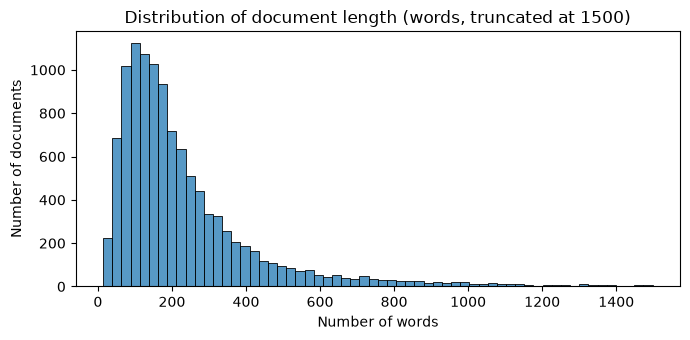

     the: 142664
      of: 67929
     god: 1587
   space: 1360
     car: 880
 windows: 1216


In [96]:
if NEWS_OK:
    lengths = pd.Series([len(d.split()) for d in docs], name="n_words")
    print(lengths.describe().round(1))

    fig, ax = plt.subplots(figsize=(7, 3.5))
    sns.histplot(lengths[lengths < 1500], bins=60, ax=ax)
    ax.set_title("Distribution of document length (words, truncated at 1500)")
    ax.set_xlabel("Number of words"); ax.set_ylabel("Number of documents")
    plt.tight_layout(); plt.show()

    counter = Counter(w for d in docs for w in d.lower().split())
    for w in ["the", "of", "god", "space", "car", "windows"]:
        print(f"{w:>8}: {counter[w]}")

Documents are very heterogeneous in length (heavy right tail), and the most frequent words are function words such as "the" and "of". Such words carry little class information, which motivates **stop-word removal** and **TF-IDF weighting** in later text-classification sessions.

---
# Exercise 3: Detecting and handling missing values

### 1. Load `employees.csv` and inspect it

In [97]:
emp_path = DATA_DIR / "employees.csv"
if emp_path.exists():
    emp = pd.read_csv(emp_path)
else:
    warnings.warn("employees.csv not found: generating a synthetic table with the same 8 columns.")
    rng = np.random.default_rng(RANDOM_STATE)
    n = 200
    emp = pd.DataFrame({
        "First Name": rng.choice(["Douglas", "Thomas", "Maria", "Jerry", "Larry", "Dennis", "Ruby"], n),
        "Gender": rng.choice(["Male", "Female"], n),
        "Start Date": pd.to_datetime("1990-01-01") + pd.to_timedelta(rng.integers(0, 12000, n), unit="D"),
        "Last Login Time": [f"{h}:{m:02d} {ap}" for h, m, ap in zip(rng.integers(1, 13, n), rng.integers(0, 60, n), rng.choice(["AM", "PM"], n))],
        "Salary": rng.integers(40000, 150000, n).astype(float),
        "Bonus %": rng.uniform(1, 20, n).round(3),
        "Senior Management": rng.choice([True, False], n).astype(object),
        "Team": rng.choice(["Marketing", "Finance", "Engineering", "Sales", "HR"], n),
    })
    emp["Start Date"] = emp["Start Date"].dt.strftime("%m/%d/%y")
    for col, frac in [("Gender", 0.08), ("First Name", 0.05), ("Salary", 0.03), ("Team", 0.04), ("Senior Management", 0.05)]:
        emp.loc[rng.random(n) < frac, col] = np.nan

print("Columns and dtypes:")
emp.info()
emp.head()

Columns and dtypes:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         189 non-null    str    
 1   Gender             186 non-null    str    
 2   Start Date         200 non-null    str    
 3   Last Login Time    200 non-null    str    
 4   Salary             198 non-null    float64
 5   Bonus %            200 non-null    float64
 6   Senior Management  184 non-null    object 
 7   Team               194 non-null    str    
dtypes: float64(2), object(1), str(5)
memory usage: 12.6+ KB


/tmp/ipykernel_59031/2707492341.py:5: UserWarning: employees.csv not found: generating a synthetic table with the same 8 columns.
  warnings.warn("employees.csv not found: generating a synthetic table with the same 8 columns.")


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,NaN,10/16/22,8:00 PM,136692.0,5.586,True,HR
1,Dennis,Female,07/17/15,10:18 PM,92525.0,7.127,NaN,Marketing
2,Larry,Male,07/12/00,9:30 PM,148324.0,3.953,True,Finance
3,Jerry,Female,12/05/21,2:55 PM,123757.0,17.612,True,Engineering
4,Jerry,Male,05/28/06,10:44 AM,111597.0,6.382,True,Sales


### 2. Count missing values per column

In [98]:
missing_before = emp.isna().sum()
print(missing_before)
print("\nTotal missing cells:", int(missing_before.sum()))

First Name           11
Gender               14
Start Date            0
Last Login Time       0
Salary                2
Bonus %               0
Senior Management    16
Team                  6
dtype: int64

Total missing cells: 49


### 3. Visualize missing-value patterns (seaborn heatmap)

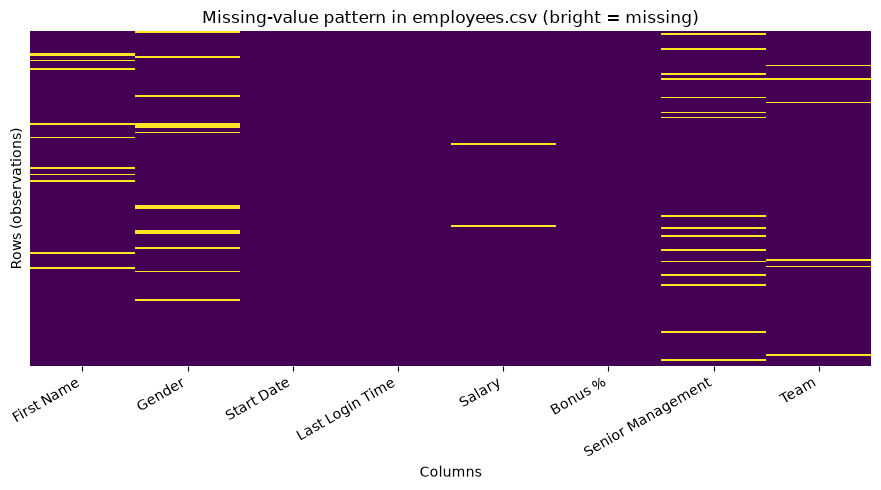

In [99]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(emp.isna(), cbar=False, cmap="viridis", yticklabels=False, ax=ax)
ax.set_title("Missing-value pattern in employees.csv (bright = missing)")
ax.set_xlabel("Columns")
ax.set_ylabel("Rows (observations)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()

Each row of the heatmap is an observation and each column a variable. Bright cells are missing. Horizontal streaks across several columns would reveal rows that are missing together, and a mostly-bright column would be a candidate to drop.

### 4. Copy the data and append a synthetic row with placeholder markers

The dataset has **eight fields**. In the synthetic row, first name is `'-'` and gender is `'na'`. The other six fields get proper missing-value markers (`np.nan`, or `pd.NaT` for datetimes).

In [100]:
emp_copy = emp.copy()

def find_col(df, name):
    
    return next(c for c in df.columns if c.strip().lower() == name)

first_col, gender_col = find_col(emp_copy, "first name"), find_col(emp_copy, "gender")

synthetic = {c: np.nan for c in emp_copy.columns}     
synthetic[first_col] = "-"
synthetic[gender_col] = "na"
print("Number of fields in the synthetic row:", len(synthetic))

emp_copy = pd.concat([emp_copy, pd.DataFrame([synthetic])], ignore_index=True)
emp_copy.tail(3)

Number of fields in the synthetic row: 8


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
198,Maria,Male,08/17/10,4:57 PM,42751.0,4.530,True,Engineering
199,Ruby,Male,02/09/11,6:30 PM,72932.0,10.918,True,Marketing
200,-,na,NaN,NaN,NaN,NaN,NaN,NaN


### 5. Recount missing values

In [101]:
missing_marker = emp_copy.isna().sum()
comparison = pd.DataFrame({
    "original": missing_before,
    "after appending row": missing_marker,
    "difference": missing_marker - missing_before,
})
comparison

,original,after appending row,difference
First Name,11,11,0
Gender,14,14,0
Start Date,0,1,1
Last Login Time,0,1,1
Salary,2,3,1
Bonus %,0,1,1
Senior Management,16,17,1
Team,6,7,1


**Why `'-'` and `'na'` are not treated as missing.** `isna()` only recognises *true* missing-value objects (`np.nan`, `None`, `pd.NaT`, `pd.NA`). To pandas, `'-'` and `'na'` are ordinary non-empty **strings**, indistinguishable in kind from `'Male'`. Only the six `np.nan` fields were counted (the difference above is +1 for the six other columns, but **0 for first name and gender**). Those two placeholders are therefore silent errors: they would count as extra categories (a "gender" called `na`) and would not be imputed. (When reading a file, `pd.read_csv(..., na_values=[...])` can declare such markers up front. Note that `read_csv` already treats strings like `'NA'`, `'N/A'`, `''` and `'nan'` as missing by default, but not `'-'` or lowercase `'na'`.)

### 6. Convert the placeholder markers to `np.nan`

**Documented, case-consistent rule:** for every text column, strip whitespace, lower-case the value, and if it belongs to the marker set `{'-', 'na', 'n/a', 'null', 'none', ''}`, replace it with `np.nan`. Real values keep their original spelling.

In [102]:
PLACEHOLDERS = {"-", "na", "n/a", "null", "none", ""}     

def placeholders_to_nan(df, markers=PLACEHOLDERS):
    out = df.copy()
    for col in out.select_dtypes(include="object").columns:
        s = out[col]
        is_marker = s.notna() & s.astype(str).str.strip().str.lower().isin(markers)
        out.loc[is_marker, col] = np.nan
    return out

emp_clean = placeholders_to_nan(emp_copy)

print("Missing values after converting markers:")
pd.DataFrame({
    "before conversion": emp_copy.isna().sum(),
    "after conversion": emp_clean.isna().sum(),
})

/tmp/ipykernel_59031/3657140463.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in out.select_dtypes(include="object").columns:


Missing values after converting markers:


,before conversion,after conversion
First Name,11,12
Gender,14,15
Start Date,1,1
Last Login Time,1,1
Salary,3,3
Bonus %,1,1
Senior Management,17,17
Team,7,7


Now the synthetic row is counted as missing in **all eight** columns (first name and gender have increased by one).

### 7. Impute with `SimpleImputer`

Strategy per column type:

| Column type | Columns | Strategy | Reason |
|---|---|---|---|
| Numerical | `Salary`, `Bonus %` | `median` | Robust to outliers and skew (salary is typically right-skewed). |
| Categorical | `Gender`, `Senior Management`, `Team` | `most_frequent` | A mean is undefined for categories, so use the mode. |
| Identifier | `First Name` | **not imputed** | A name is an identifier, not a feature with a "typical value". Filling it with the most frequent name would invent false identities. Keep it as missing, or drop the rows if the name is needed. |
| Date/time strings | `Start Date`, `Last Login Time` | not imputed here | Convert with `pd.to_datetime` first, then decide on a dedicated rule. |

> The **dataset-wide** imputation below answers the exercise. A **leakage-safe** version (fit on train only) follows right after.

In [103]:
num_cols = [c for c in emp_clean.select_dtypes(include="number").columns]
id_cols = [first_col]
date_cols = [c for c in emp_clean.columns if "date" in c.lower() or "time" in c.lower()]
cat_cols = [c for c in emp_clean.columns if c not in num_cols + id_cols + date_cols]

print("numerical  :", num_cols)
print("categorical:", cat_cols)
print("identifier :", id_cols, "(not imputed)")
print("date/time  :", date_cols, "(not imputed here)")

emp_imputed = emp_clean.copy()

emp_imputed[cat_cols] = emp_imputed[cat_cols].astype(object)

emp_imputed[num_cols] = SimpleImputer(strategy="median").fit_transform(emp_imputed[num_cols])
emp_imputed[cat_cols] = SimpleImputer(strategy="most_frequent").fit_transform(emp_imputed[cat_cols])
emp_imputed.tail(3)

numerical  : ['Salary', 'Bonus %']
categorical: ['Gender', 'Senior Management', 'Team']
identifier : ['First Name'] (not imputed)
date/time  : ['Start Date', 'Last Login Time'] (not imputed here)


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
198,Maria,Male,08/17/10,4:57 PM,42751.0,4.530,True,Engineering
199,Ruby,Male,02/09/11,6:30 PM,72932.0,10.918,True,Marketing
200,NaN,Male,NaN,NaN,98725.5,9.820,True,Sales


### 8. Missing-value counts before and after preprocessing

,original file,after adding row + markers->NaN,after imputation
First Name,11,12,12
Gender,14,15,0
Start Date,0,1,1
Last Login Time,0,1,1
Salary,2,3,0
Bonus %,0,1,0
Senior Management,16,17,0
Team,6,7,0


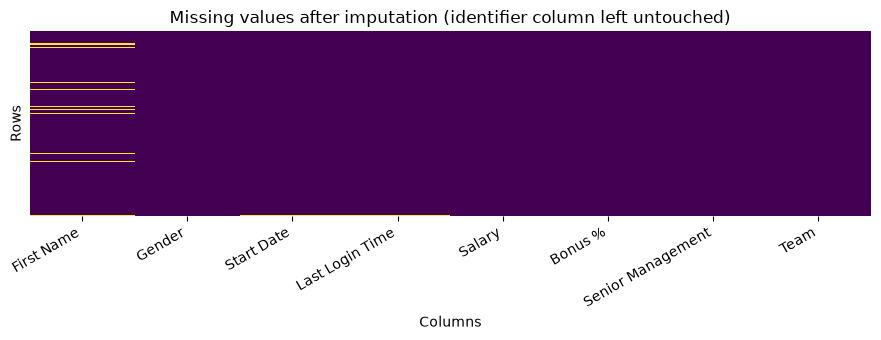

In [104]:
summary = pd.DataFrame({
    "original file": emp.isna().sum(),
    "after adding row + markers->NaN": emp_clean.isna().sum(),
    "after imputation": emp_imputed.isna().sum(),
})
display(summary)

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(emp_imputed.isna(), cbar=False, cmap="viridis", yticklabels=False, ax=ax)
ax.set_title("Missing values after imputation (identifier column left untouched)")
ax.set_xlabel("Columns"); ax.set_ylabel("Rows")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

**Limitations of imputation**

* It **invents values**. Imputed entries are guesses, not observations.
* Median/mode imputation **shrinks variance** and distorts distributions and correlations (many rows get the *same* value). Mode imputation inflates the majority category.
* It assumes data are **Missing Completely At Random**. If missingness depends on the value itself or on other variables (e.g. high earners hide their salary), single imputation introduces **bias**.
* It hides the fact that something was missing. Adding a **missing-indicator** (`SimpleImputer(add_indicator=True)`) can preserve this signal.
* It ignores relationships between features. Model-based imputers (`KNNImputer`, `IterativeImputer`) can do better at higher cost.
* If a column is mostly missing, imputation is unreliable and dropping the column may be better.

### Important: leakage-safe imputation (fit on the training data only)

The imputation above used statistics from **all** rows. That is fine for the exploratory exercise. When preparing data for a **predictive model**, the median/mode must be learned from the training rows only. A `Pipeline`/`ColumnTransformer` makes this automatic.

In [105]:
train_df, test_df = train_test_split(emp_clean, test_size=0.20, random_state=RANDOM_STATE)

preprocess = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", SimpleImputer(strategy="most_frequent"), cat_cols),
    ],
    remainder="drop",            
)

train_imp = preprocess.fit_transform(train_df.astype({c: object for c in cat_cols}))   
test_imp  = preprocess.transform(test_df.astype({c: object for c in cat_cols}))        

print("Learned medians (from train only)      :", dict(zip(num_cols, preprocess.named_transformers_["num"].statistics_)))
print("Learned most-frequent (from train only):", dict(zip(cat_cols, preprocess.named_transformers_["cat"].statistics_)))
print("train shape:", train_imp.shape, "| test shape:", test_imp.shape)

Learned medians (from train only)      : {'Salary': np.float64(100652.0), 'Bonus %': np.float64(9.755)}
Learned most-frequent (from train only): {'Gender': 'Male', 'Senior Management': True, 'Team': 'Sales'}
train shape: (160, 5) | test shape: (41, 5)


---
# Exercise 4: Feature scaling, binarization, and categorical encoding

## Part A. Scaling and binarization

### 1 and 2. Apply the five methods and display the results

In [106]:
X_num = np.array([[1, -1,  2],
                  [2,  0,  0],
                  [0,  1, -1]], dtype=float)
cols = ["Feature 1", "Feature 2", "Feature 3"]
show = lambda arr: pd.DataFrame(np.round(arr, 3), columns=cols)

print("Original matrix"); display(show(X_num))

results = {
    "StandardScaler":  StandardScaler().fit_transform(X_num), 
    "MinMaxScaler":    MinMaxScaler().fit_transform(X_num),     
    "MaxAbsScaler":    MaxAbsScaler().fit_transform(X_num),     
    "RobustScaler":    RobustScaler().fit_transform(X_num),     
    "normalize (L2)":  normalize(X_num, norm="l2"),             
}
for name, arr in results.items():
    print(name); display(show(arr))

Original matrix


,Feature 1,Feature 2,Feature 3
0,1.0,-1.0,2.0
1,2.0,0.0,0.0
2,0.0,1.0,-1.0


StandardScaler


,Feature 1,Feature 2,Feature 3
0,0.000,-1.225,1.336
1,1.225,0.000,-0.267
2,-1.225,1.225,-1.069


MinMaxScaler


...

,Feature 1,Feature 2,Feature 3
0,0.5,-1.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,-0.5


RobustScaler


,Feature 1,Feature 2,Feature 3
0,0.0,-1.0,1.333
1,1.0,0.0,0.000
2,-1.0,1.0,-0.667


normalize (L2)


,Feature 1,Feature 2,Feature 3
0,0.408,-0.408,0.816
1,1.000,0.000,0.000
2,0.000,0.707,-0.707


In [107]:
print("Column means / stds after StandardScaler :", results["StandardScaler"].mean(0).round(3), results["StandardScaler"].std(0).round(3))
print("Column min / max after MinMaxScaler      :", results["MinMaxScaler"].min(0), results["MinMaxScaler"].max(0))
print("Column max |x| after MaxAbsScaler        :", np.abs(results["MaxAbsScaler"]).max(0))
print("Column medians after RobustScaler        :", np.median(results["RobustScaler"], axis=0))
print("Row L2 norms after normalize             :", np.linalg.norm(results["normalize (L2)"], axis=1).round(3))

Column means / stds after StandardScaler : [0. 0. 0.] [1. 1. 1.]
Column min / max after MinMaxScaler      : [0. 0. 0.] [1. 1. 1.]
Column max |x| after MaxAbsScaler        : [1. 1. 1.]
Column medians after RobustScaler        : [0. 0. 0.]
Row L2 norms after normalize             : [1. 1. 1.]


### 3. Main idea of each method

| Method | Formula / idea | Acts on | Notes |
|---|---|---|---|
| `StandardScaler` | `(x - mean) / std`: zero mean, unit variance | **each feature** (column) | Standard choice for many models. Sensitive to outliers (mean and std are not robust). |
| `MinMaxScaler` | `(x - min) / (max - min)`: maps to `[0, 1]` | **each feature** | Preserves the shape of the distribution. Very sensitive to outliers (they set min and max). |
| `MaxAbsScaler` | `x / max(|x|)`: maps to `[-1, 1]` | **each feature** | Does not shift or centre the data, so it **preserves sparsity** and zeros. |
| `RobustScaler` | `(x - median) / IQR` | **each feature** | Uses median and interquartile range, so it is **robust to outliers**. |
| `normalize` | divides each row by its norm (L2 by default) | **each sample** (row) | Gives each row unit length. Useful for cosine similarity and text vectors. It is *normalization*, not feature scaling, and it needs no fitting. |

**Scalers vs. `normalize`:** the four `*Scaler` classes are *fit* on the columns of the training data (they store statistics, then `transform` new data with them). `normalize` is a stateless row-wise function.

### 4. Binarization with an explicit threshold

In [108]:
THRESHOLD = 0.5     
X_bin = Binarizer(threshold=THRESHOLD).fit_transform(X_num)
print(f"Binarized with threshold = {THRESHOLD}"); display(show(X_bin))

for t in (-0.5, 0.5, 1.5):
    print(f"threshold={t:>4}: number of ones =", int(Binarizer(threshold=t).fit_transform(X_num).sum()))

Binarized with threshold = 0.5


,Feature 1,Feature 2,Feature 3
0,1.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0


threshold=-0.5: number of ones = 7
threshold= 0.5: number of ones = 4
threshold= 1.5: number of ones = 2


**Effect of the threshold.** A value becomes **1 if it is strictly greater than the threshold** and **0 otherwise** (a value *equal* to the threshold becomes 0). Raising the threshold produces fewer ones (a sparser output). Lowering it produces more ones. With a threshold of 0.5, the matrix keeps only the entries 1 and 2, and everything else (0, -1) maps to 0, so all information about magnitude and sign among the "small" values is lost. The threshold is a modelling choice and should be justified by the application (e.g. "pixel is bright", "word occurs at least once" uses threshold 0).

### Discussion: Why does scaling matter, and is it always necessary for trees?

* **k-nearest neighbours** rely on distances. A feature with a large range (e.g. salary in the thousands) dominates one with a small range (e.g. a ratio in 0-1), so "nearest" is determined almost entirely by the large feature.
* **SVMs** (especially with RBF or polynomial kernels) depend on distances or dot products, and the margin is distorted when features have different scales. Regularization also penalizes weights unevenly.
* **Gradient-based models** (linear/logistic regression, neural networks) have an elongated loss surface when features have different scales. Gradient descent then zig-zags and converges slowly, or needs a tiny learning rate. Regularized models (Ridge/Lasso) also penalise coefficients unequally depending on feature scale. Scaling usually speeds up and stabilises training.
* **Decision trees** (and random forests, gradient-boosted trees) are **not** scale-sensitive in general. Each split only compares one feature to a threshold, and any monotonic rescaling keeps the same ordering and therefore the same splits. Scaling is *not necessary* for them (though it does no harm).

## Part B. Encoding categorical variables

### Data

In [109]:
df_cat = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target":    ["US", "France", "Japan", "Algeria"],
})
X_cat = df_cat[["Feature 1", "Feature 2", "Feature 3"]]
y_cat = df_cat["Target"]
df_cat

,Feature 1,Feature 2,Feature 3,Target
0,male,from US,uses Safari,US
1,female,from Europe,uses Safari,France
2,female,from Asia,uses Firefox,Japan
3,male,from Africa,uses Chrome,Algeria


### 1. `OrdinalEncoder` on the three input features

In [110]:
ord_enc = OrdinalEncoder()
X_cat_ord = ord_enc.fit_transform(X_cat)

print("categories_ (index in each array = assigned code):")
for name, cats in zip(X_cat.columns, ord_enc.categories_):
    print(f"  {name}: {dict(zip(cats, range(len(cats))))}")

display(pd.DataFrame(X_cat_ord.astype(int), columns=X_cat.columns))

categories_ (index in each array = assigned code):
  Feature 1: {'female': 0, 'male': 1}
  Feature 2: {'from Africa': 0, 'from Asia': 1, 'from Europe': 2, 'from US': 3}
  Feature 3: {'uses Chrome': 0, 'uses Firefox': 1, 'uses Safari': 2}


,Feature 1,Feature 2,Feature 3
0,1,3,2
1,0,2,2
2,0,1,1
3,1,0,0


`categories_` is a list with one array per feature, **sorted alphabetically**. The code of a category is its **position** in that array: `female -> 0`, `male -> 1`; `from Africa -> 0`, `from Asia -> 1`, `from Europe -> 2`, `from US -> 3`; and so on. These numbers are **just labels** and not a ranking. "from US" (3) is not "greater than" "from Africa" (0), yet a distance-based or linear model would treat it that way.

### 2. Encode the target separately (`LabelEncoder`)

In [111]:
label_enc = LabelEncoder()
y_enc = label_enc.fit_transform(y_cat)

print("Encoded target:", y_enc)
print("Mapping class name -> label:")
for label, name in enumerate(label_enc.classes_):
    print(f"  {name:>8} -> {label}")

Encoded target: [3 1 2 0]
Mapping class name -> label:
   Algeria -> 0
    France -> 1
     Japan -> 2
        US -> 3


`LabelEncoder` is designed for **target vectors** (1-D) while `OrdinalEncoder` is for **feature matrices** (2-D). Classes are again sorted alphabetically (`Algeria=0, France=1, Japan=2, US=3`). Decode predictions with `label_enc.inverse_transform(...)`.

### 3. `OneHotEncoder` on the target

In [112]:
ohe = OneHotEncoder(sparse_output=False)           
y_onehot = ohe.fit_transform(y_cat.to_frame())     

print("Categories:", ohe.categories_[0])
display(pd.DataFrame(y_onehot.astype(int), columns=ohe.categories_[0], index=y_cat.values))

Categories: ['Algeria' 'France' 'Japan' 'US']


,Algeria,France,Japan,US
US,0,0,0,1
France,0,1,0,0
Japan,0,0,1,0
Algeria,1,0,0,0


**Integer (label) encoding vs. one-hot encoding**

| | Integer / label encoding | One-hot encoding |
|---|---|---|
| Representation | One column of integers (0, 1, 2, 3) | One **binary column per category** (a single 1 per row) |
| Implied order | Yes (0 < 1 < 2 < 3), which is misleading for nominal data | None: categories are treated as equidistant |
| Dimensionality | 1 column | `k` columns (can be large for high-cardinality variables) |
| Typical use | Target labels for classifiers, ordinal variables, tree models | Nominal features for linear models, SVM, kNN, neural networks. Targets for multi-class neural nets with softmax |

### 4. Why one-hot is preferable for nominal input features

Ordinal codes impose an **artificial order and spacing**. A linear model, kNN, or SVM would conclude that Africa (0) is closer to Asia (1) than to the US (3), and that the effect of "from US" is three times that of "from Asia". None of this is true for nominal categories. One-hot encoding gives every category its own independent dimension, so every pair of categories is equally far apart and the model can learn a separate weight for each. The cost is higher dimensionality (watch out for rare categories and high cardinality, where grouping rare levels or target encoding is better). Some models (tree ensembles) cope with ordinal codes reasonably, but even then one-hot is the safer default for nominal inputs. Also remember `handle_unknown="ignore"` so that unseen categories at test time do not raise errors.

In [113]:
ohe_X = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_cat_ohe = ohe_X.fit_transform(X_cat)
pd.DataFrame(X_cat_ohe.astype(int), columns=ohe_X.get_feature_names_out(X_cat.columns))

,Feature 1_female,Feature 1_male,Feature 2_from Africa,Feature 2_from Asia,Feature 2_from Europe,Feature 2_from US,Feature 3_uses Chrome,Feature 3_uses Firefox,Feature 3_uses Safari
0,0,1,0,0,0,1,0,0,1
1,1,0,0,0,1,0,0,0,1
2,1,0,0,1,0,0,0,1,0
3,0,1,1,0,0,0,1,0,0


---
# Conclusion: which preprocessing is appropriate for which data type?

| Data type | Appropriate operations | Notes / pitfalls |
|---|---|---|
| **Numerical** | Handle missing values (`median` or `mean` imputation, or model-based). Scale (`StandardScaler`, `MinMaxScaler`, `RobustScaler` if outliers, `MaxAbsScaler` for sparse data). Binarize with a justified threshold. Row-wise `normalize` for similarity-based methods. | Scaling matters for kNN, SVM, gradient-based models, and PCA, but not for tree-based models. Fit scalers on the **training set only**. |
| **Categorical (nominal)** | Convert placeholders (`'-'`, `'na'`) to `NaN` with a documented rule. Impute with `most_frequent` (or a separate "missing" category). Encode with **one-hot**. | Ordinal codes imply a false order. Use `handle_unknown="ignore"` and consider grouping rare categories. |
| **Categorical (ordinal) and targets** | `OrdinalEncoder` with an explicit category order (for ordinal features), `LabelEncoder` (for target labels). One-hot targets only when the model requires it (e.g. softmax output). | Integer codes of a *target* are fine, since the model never treats them as distances. |
| **Identifiers** | Usually **exclude** them from the model input. Never impute them without justification. | Identifiers can leak information or cause overfitting. |
| **Text** | Read with an explicit encoding. Inspect (length, vocabulary, class balance). Convert to numerical vectors (bag-of-words, TF-IDF) after cleaning (lower-casing, stop-word removal). | Raw strings cannot be fed to models. The vectorizer's vocabulary must be learned on **training** documents only. |

**Cross-cutting good practice:** keep the raw data unchanged and experiment on copies. Check dtypes and category values before preprocessing. Fix `random_state` for reproducibility. Use stratified splitting for classification. Above all, **fit every preprocessing step on the training data only** (ideally inside a `Pipeline`/`ColumnTransformer`) and apply it to validation and test data, so that the test set stays a faithful simulation of unseen data and no data leakage occurs.